# Human stromal: cell-type annotation (stage 04c)

Every cluster of the re-integrated stromal lineage is assigned one cell type (or EXCLUDE). Labels are the vocabulary in resources/annotation_vocabulary.yaml.

Clustering: `data/interim/latent_human_stromal.h5ad`, column `leiden_scVI_3.0`. Decisions: `resources/annotations/human_stromal.csv`, one
row per cluster with the markers that justify the label in `note`. Nothing in this
notebook assigns a label; it shows the evidence the table was decided from.

In [1]:
import warnings
from pathlib import Path

import anndata as ad
import numpy as np
import pandas as pd
import scanpy as sc

# Notebook kernels start in notebooks/annotation/, so the repo root is two levels up.
REPO = Path("../..").resolve()
if not (REPO / "resources/annotations").is_dir():
    raise FileNotFoundError(f"{REPO} is not the repository root")
SPECIES, LEVEL, RESOLUTION = "human", "stromal", "leiden_scVI_3.0"
OBJECT = REPO / "data/interim/latent_human_stromal.h5ad"
TABLE = REPO / "resources/annotations/human_stromal.csv"
PANEL = ['PDGFRA', 'DCN', 'LUM', 'COL1A1', 'PRL', 'IGFBP1', 'LEFTY2', 'FOXO1', 'MKI67', 'TOP2A', 'CDH1', 'PECAM1', 'PTPRC', 'ACTA2', 'RGS5', 'NOTCH3', 'MCAM', 'PDGFRB']
sc.settings.set_figure_params(dpi=80, frameon=False)
pd.set_option("display.max_colwidth", 200)

## 1. The committed table

In [2]:
table = pd.read_csv(TABLE, dtype={"cluster": str})
table.set_index("cluster")

,label,n_cells,res,note
cluster,,,,
0,decidual_cell,1970,leiden_scVI_3.0,"PRL 0.05; IGFBP1 0.25; LEFTY2 0.44; FOXO1 0.96 | top vs level: MMP10 0.88, PRXL2A 0.89, NEAT1 0.99"
1,decidual_cell,1994,leiden_scVI_3.0,"PRL 0.02; IGFBP1 0.13; LEFTY2 0.52; FOXO1 0.90 | top vs level: FAM155A 0.91, CASC15 0.92, ADAMTS9 0.87"
2,decidual_cell,2057,leiden_scVI_3.0,"PRL 0.00; IGFBP1 0.04; LEFTY2 0.53; FOXO1 0.84 | top vs level: ATG5 0.91, SOX4 0.88, SYT1 0.83"
3,decidual_cell,1734,leiden_scVI_3.0,"PRL 0.01; IGFBP1 0.02; LEFTY2 0.25; FOXO1 0.85 | top vs level: MMP11 0.79, FAM155A 0.86, PCSK5 0.80"
4,decidual_cell,794,leiden_scVI_3.0,"PRL 0.02; IGFBP1 0.16; LEFTY2 0.70; FOXO1 0.96 | top vs level: KIF26B 0.82, DIO2 0.88, LUM 0.90"
5,decidual_cell,1014,leiden_scVI_3.0,"PRL 0.00; IGFBP1 0.04; LEFTY2 0.62; FOXO1 0.81 | top vs level: ADAMTS9 0.88, IGFBP3 0.90, LUM 0.82"
6,decidual_cell,3081,leiden_scVI_3.0,"PRL 0.02; IGFBP1 0.07; LEFTY2 0.37; FOXO1 0.93 | top vs level: VMP1 0.96, MMP10 0.87, PTPRE 0.82"
7,endometrial_fibroblast,1510,leiden_scVI_3.0,"PDGFRA 0.59; DCN 0.77; LUM 0.27; PRL 0.00 | top vs level: KCNIP4 0.95, ADAMTS19 0.82, ULK4 0.83"
8,decidual_cell,2088,leiden_scVI_3.0,"PRL 0.00; IGFBP1 0.02; LEFTY2 0.52; FOXO1 0.73 | top vs level: EEF1A1 0.79, TMSB4X 0.85, RPLP1 0.70"


## 2. The clustered object (must carry exactly the clusters in the table)

In [3]:
adata = ad.read_h5ad(OBJECT)
adata.obs["cluster"] = adata.obs[RESOLUTION].astype(str)
in_object, in_table = set(adata.obs["cluster"]), set(table["cluster"])
if in_object != in_table:
    raise ValueError(f"cluster sets differ: object-only {sorted(in_object - in_table)}, "
                     f"table-only {sorted(in_table - in_object)}")
labels = table.set_index("cluster")["label"]
adata.obs["label"] = adata.obs["cluster"].map(labels).astype("category")
print(adata.n_obs, "nuclei;", len(in_object), "clusters")
print(adata.obs["label"].value_counts().to_dict())

48004 nuclei; 34 clusters
{'endometrial_fibroblast': 24425, 'decidual_cell': 23108, 'perivascular_cell': 471}


In [4]:
# Expression for the dot plot: CP10K log1p from raw counts.
counts = adata.layers["counts"] if "counts" in adata.layers else adata.X
expr = ad.AnnData(X=counts.copy(), obs=adata.obs[["cluster", "label"]].copy(),
                  var=adata.var[[]].copy())
sc.pp.normalize_total(expr, target_sum=1e4)
sc.pp.log1p(expr)
genes = [g for g in PANEL if g in expr.var_names]
missing = sorted(set(PANEL) - set(genes))
if missing:
    print("not in this object:", missing)

## 3. Marker dot plot by cluster

Dot size is the fraction of nuclei in which the gene is detected, colour the mean
log1p CP10K. Clusters are grouped by their label; EXCLUDE clusters are last.

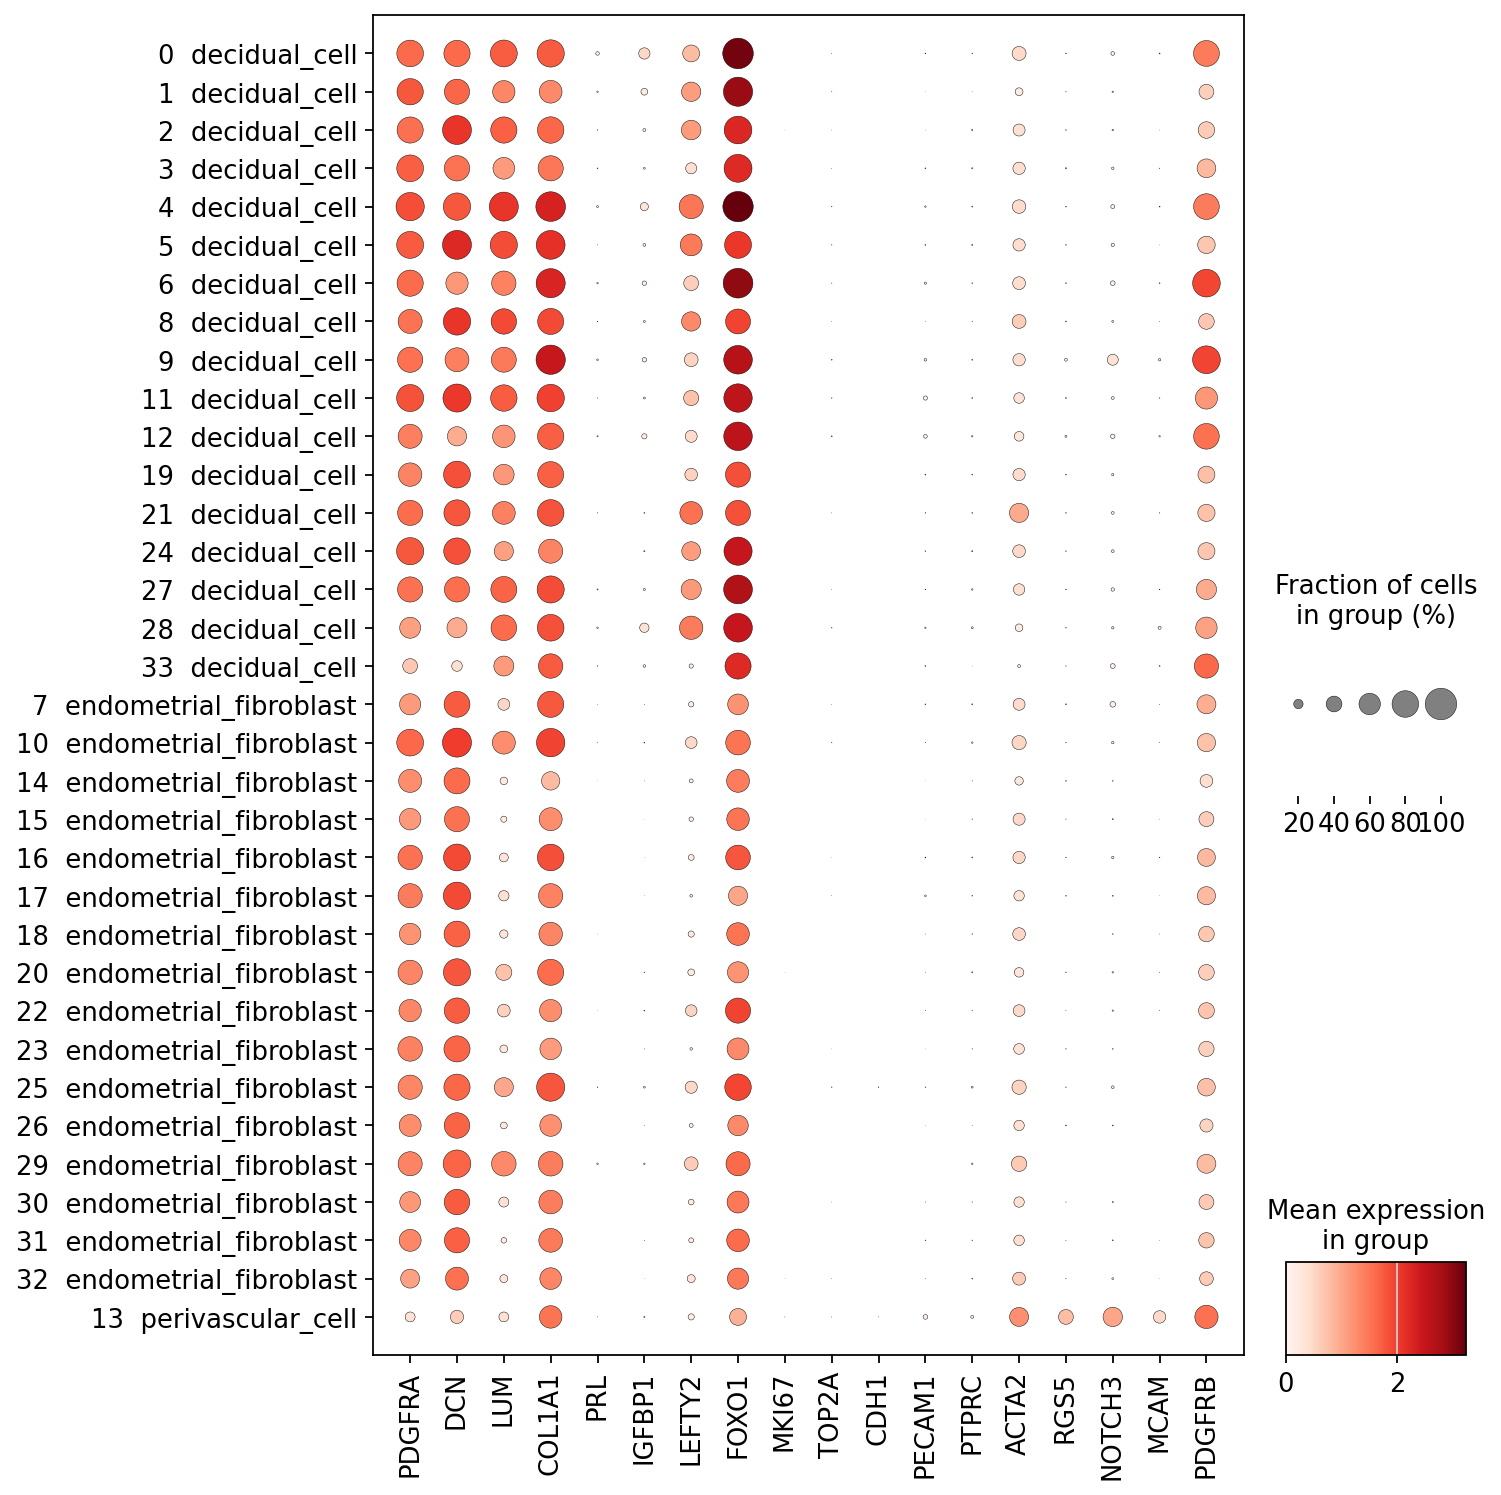

In [5]:
def sort_key(c):
    return (labels[c] == "EXCLUDE", labels[c], int(c) if c.isdigit() else c)

order = sorted(in_object, key=sort_key)
expr.obs["cluster_labelled"] = pd.Categorical(
    [f"{c}  {labels[c]}" for c in expr.obs["cluster"]],
    categories=[f"{c}  {labels[c]}" for c in order])
sc.pl.dotplot(expr, genes, groupby="cluster_labelled", standard_scale=None,
              figsize=(0.32 * len(genes) + 3, 0.28 * len(order) + 1.5))

## 4. QC per cluster

Median DoubletDetection score and genes per nucleus per cluster, with the lineage
median for reference (the CSV notes quote the lineage's doublet 75th and genes 25th
percentiles, from `tools/cluster_marker_table.py`). A high doublet score together
with markers of another lineage (section 6) is what an EXCLUDE call rests on; a
moderate score alone is not (cycling clusters score around 1 throughout this
dataset).

In [6]:
qc_cols = [c for c in ("doubletdetection_doublet_score", "n_genes_by_counts",
                       "total_counts") if c in adata.obs]
qc = adata.obs.groupby("cluster", observed=True)[qc_cols].median().loc[order]
qc.insert(0, "n", adata.obs["cluster"].value_counts().loc[order])
qc.insert(1, "label", labels.loc[order])
qc.loc["lineage median"] = [adata.n_obs, ""] + list(adata.obs[qc_cols].median())
qc.round(2)

,n,label,doubletdetection_doublet_score,n_genes_by_counts,total_counts
cluster,,,,,
0,1970,decidual_cell,0.01,2464.5,4862.0
1,1994,decidual_cell,0.00,1627.5,3011.5
2,2057,decidual_cell,0.05,2183.0,4029.0
3,1734,decidual_cell,0.03,2061.0,3850.5
4,794,decidual_cell,0.10,2432.0,4639.0
5,1014,decidual_cell,0.04,2116.0,3763.0
6,3081,decidual_cell,0.01,2145.0,4161.0
8,2088,decidual_cell,0.00,1450.0,2396.0
9,1155,decidual_cell,0.02,2177.0,3970.0


## 5. UMAP by cluster and by label

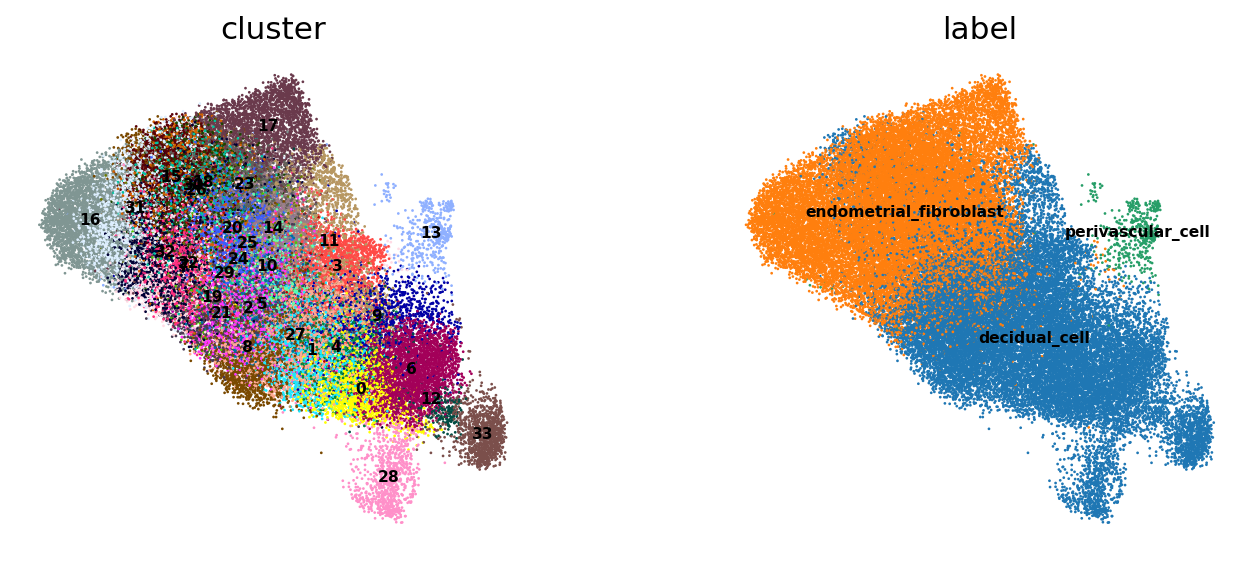

In [7]:
umap_key = next((k for k in ("X_umap_scVI", "X_umap") if k in adata.obsm), None)
if umap_key is None:
    latent_key = next(k for k in adata.obsm if "scVI" in k or "scvi" in k)
    sc.pp.neighbors(adata, use_rep=latent_key, n_neighbors=15, random_state=0)
    sc.tl.umap(adata, random_state=0)
    umap_key = "X_umap"
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    sc.pl.embedding(adata, basis=umap_key, color=["cluster", "label"], legend_loc="on data",
                    legend_fontsize=7, size=6, ncols=2, wspace=0.25)

## 6. EXCLUDE clusters

Detection of each lineage's markers inside the excluded clusters, next to the
lineage-wide detection; a cluster is excluded when it carries another lineage's
programme (doublets) or too little RNA to call.

In [8]:
excluded = [c for c in order if labels[c] == "EXCLUDE"]
if excluded:
    detected = pd.DataFrame(
        {c: np.asarray((expr[expr.obs["cluster"] == c, genes].X > 0).mean(0)).ravel()
         for c in excluded},
        index=genes)
    detected["lineage"] = np.asarray((expr[:, genes].X > 0).mean(0)).ravel()
    display(detected.round(2).T)
else:
    print("no EXCLUDE clusters in this table")

no EXCLUDE clusters in this table
